[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miguelmalgon-sys/proyecto-ciencia-datos-spotify/blob/main/notebook/proyecto_ciencia_datos.ipynb)

# ¿Qué hace popular a una canción? Análisis de datos de Spotify
**Curso de Ciencia de Datos · Proyecto final**
**Integrantes:** (nombres del equipo)

## Etapa 1: Fundamentos y preparación de datos

### 1. Selección del dataset y justificación
Para este proyecto trabajamos con un conjunto de datos públicos de Spotify (TidyTuesday, enero de 2020) que reúne cerca de 33 mil canciones. Cada una trae características de audio (danceability, energy, valence, tempo, entre otras), su popularidad, el género de la playlist y la fecha de lanzamiento.

Lo elegimos porque es un caso realista de una plataforma de streaming, tiene variables numéricas y categóricas, y presenta problemas de calidad que se ven en la práctica (valores nulos, registros repetidos y fechas en formatos distintos), lo que lo hace adecuado para practicar la limpieza de datos.

**Relación con nuestra carrera:** (completar con 2 o 3 líneas sobre cómo se conecta con la carrera del equipo).

**Pregunta que guía el proyecto:** ¿qué características de audio se asocian con la popularidad de una canción y cómo cambian según el género?

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
URL='https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv'
try: df=pd.read_csv('../datos/spotify_songs_raw.csv')   # si tenemos el repositorio clonado
except FileNotFoundError: df=pd.read_csv(URL)            # si estamos en Colab, lo descargamos
df.shape

(32833, 23)

### 2. Exploración inicial
Primero revisamos las dimensiones, los tipos de variables, los valores nulos y las distribuciones.

In [ ]:
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  str    
 1   track_name                32828 non-null  str    
 2   track_artist              32828 non-null  str    
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  str    
 5   track_album_name          32828 non-null  str    
 6   track_album_release_date  32833 non-null  str    
 7   playlist_name             32833 non-null  str    
 8   playlist_id               32833 non-null  str    
 9   playlist_genre            32833 non-null  str    
 10  playlist_subgenre         32833 non-null  str    
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudness         

In [ ]:
tipos=pd.DataFrame({'dtype':df.dtypes,'nulos':df.isna().sum(),'unicos':df.nunique()}); tipos

,dtype,nulos,unicos
track_id,str,0,28356
track_name,str,5,23449
track_artist,str,5,10692
track_popularity,int64,0,101
track_album_id,str,0,22545
track_album_name,str,5,19743
track_album_release_date,str,0,4530
playlist_name,str,0,449
playlist_id,str,0,471
playlist_genre,str,0,6


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
track_popularity,32833.0,42.477081,24.984074,0.000000,24.0000,45.000000,62.00000,100.000
danceability,32833.0,0.654850,0.145085,0.000000,0.5630,0.672000,0.76100,0.983
energy,32833.0,0.698619,0.180910,0.000175,0.5810,0.721000,0.84000,1.000
key,32833.0,5.374471,3.611657,0.000000,2.0000,6.000000,9.00000,11.000
loudness,32833.0,-6.719499,2.988436,-46.448000,-8.1710,-6.166000,-4.64500,1.275
mode,32833.0,0.565711,0.495671,0.000000,0.0000,1.000000,1.00000,1.000
speechiness,32833.0,0.107068,0.101314,0.000000,0.0410,0.062500,0.13200,0.918
acousticness,32833.0,0.175334,0.219633,0.000000,0.0151,0.080400,0.25500,0.994
instrumentalness,32833.0,0.084747,0.224230,0.000000,0.0000,0.000016,0.00483,0.994
liveness,32833.0,0.190176,0.154317,0.000000,0.0927,0.127000,0.24800,0.996


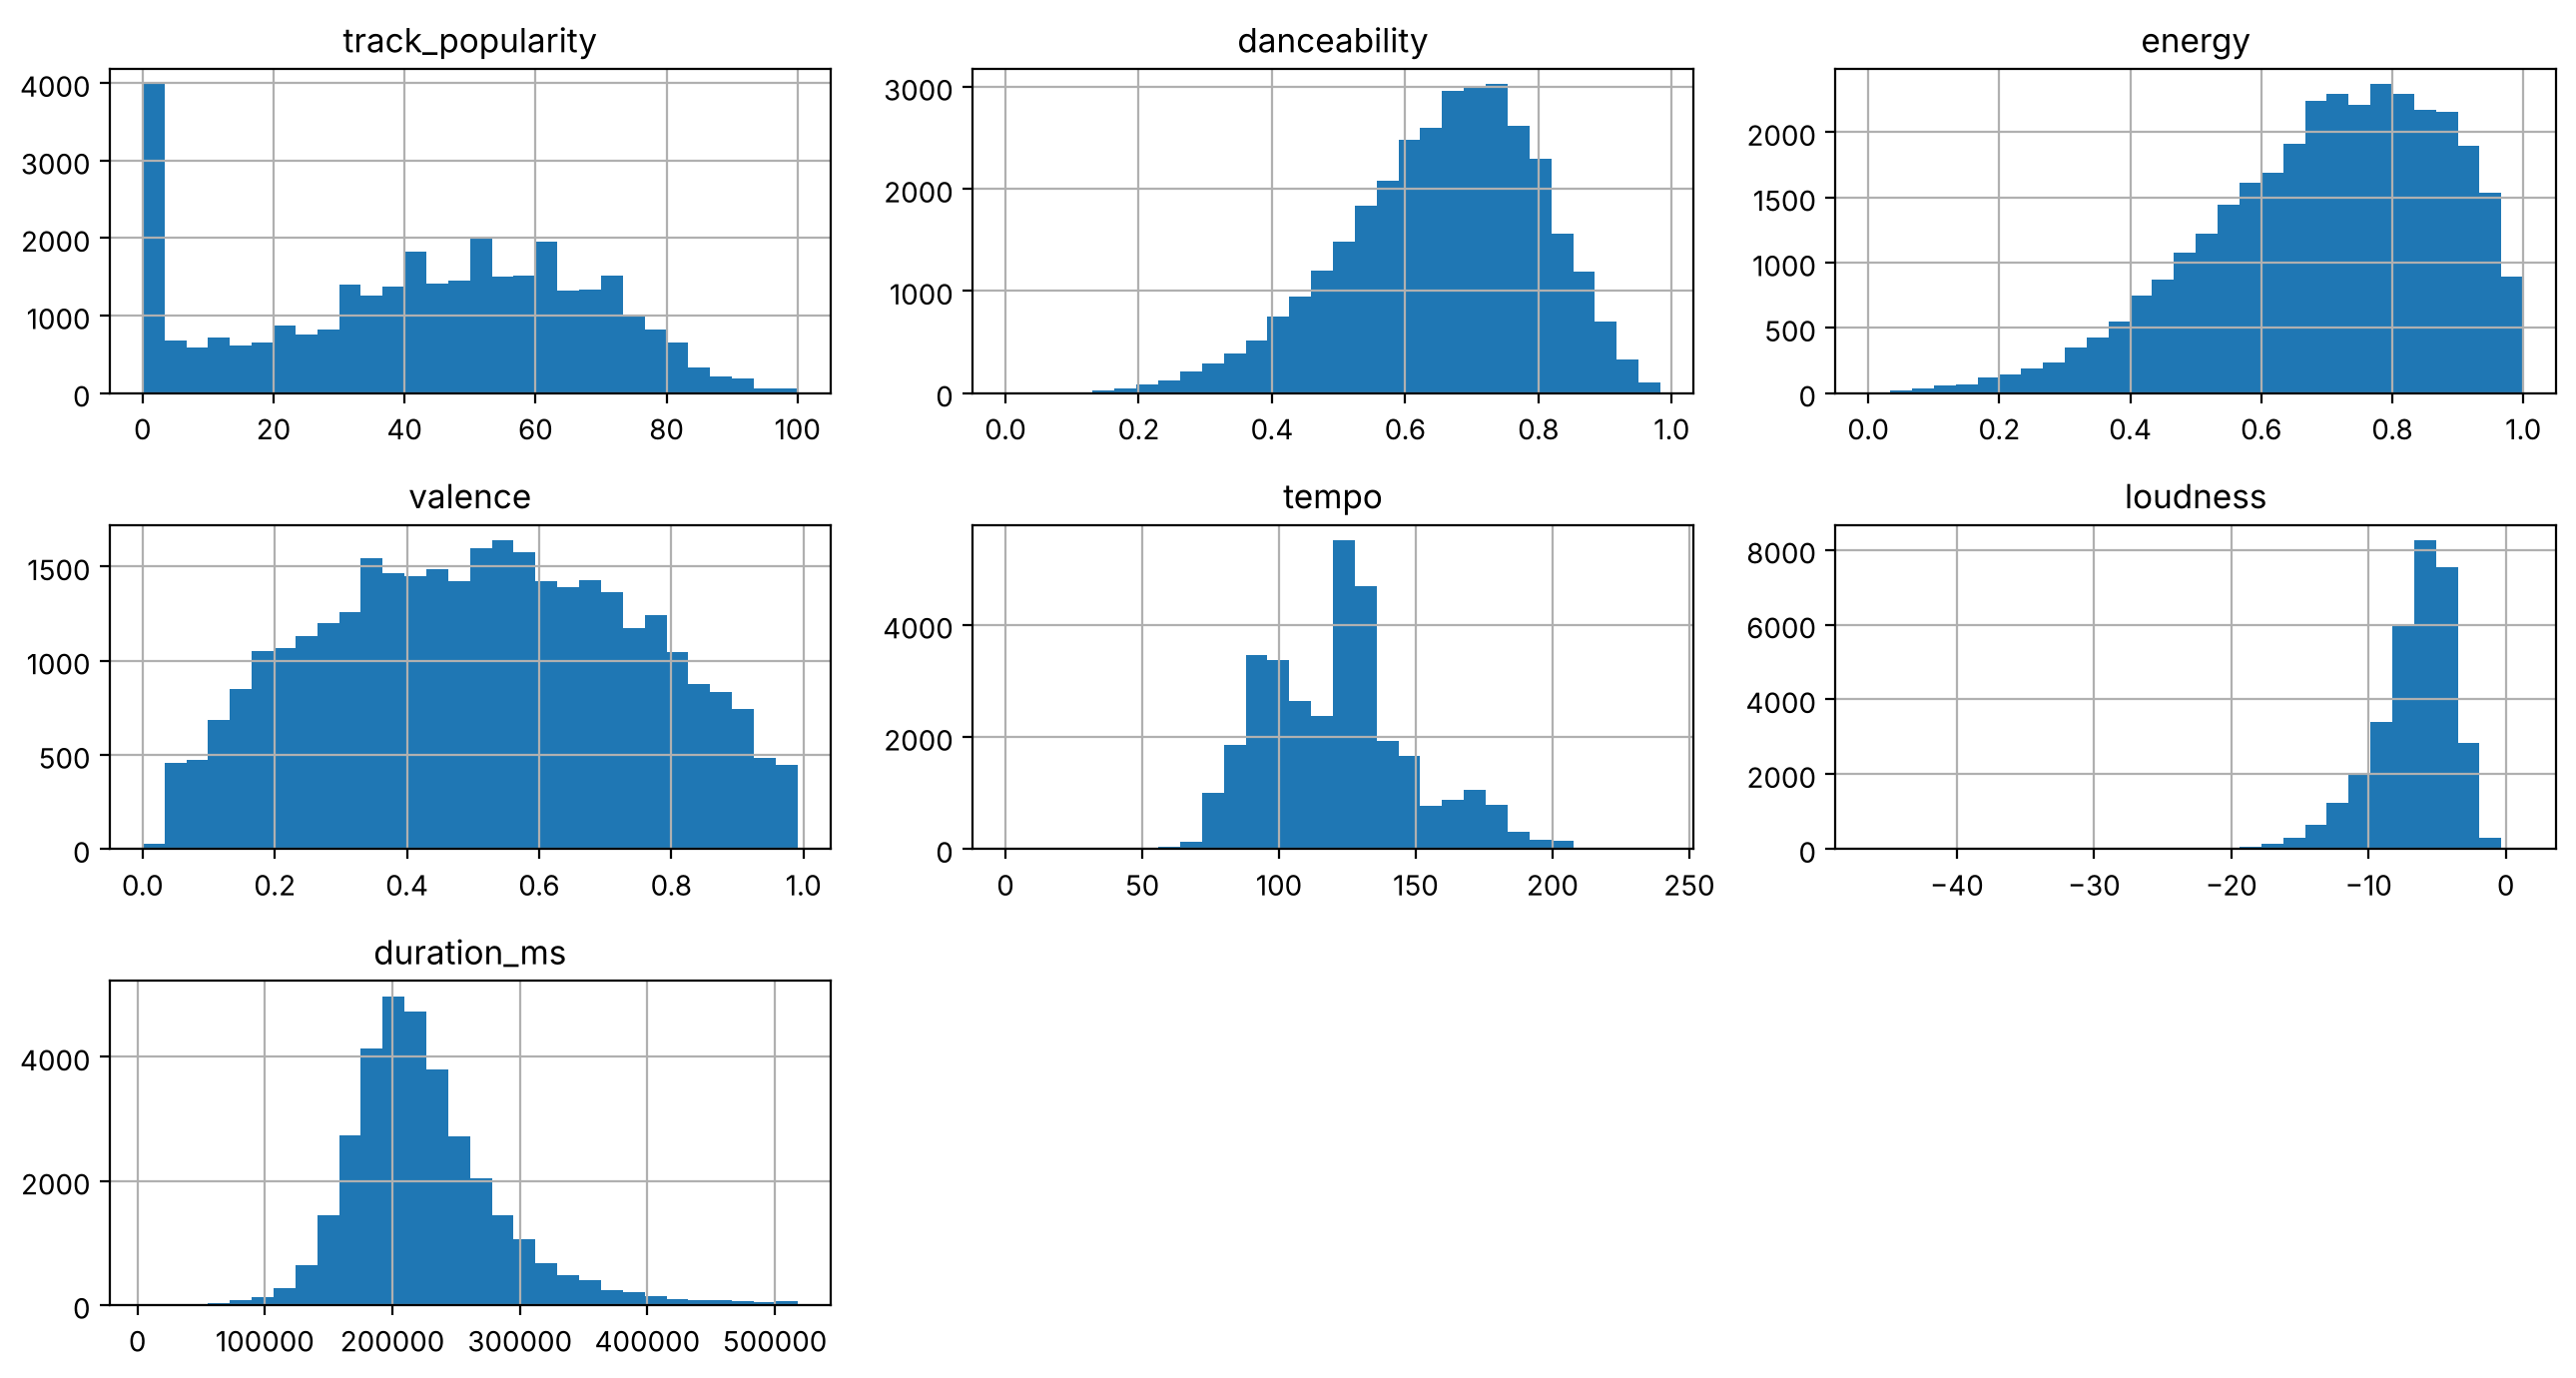

In [ ]:
df[['track_popularity','danceability','energy','valence','tempo','loudness','duration_ms']].hist(bins=30,figsize=(13,7));plt.tight_layout();plt.show()

In [ ]:
print('Filas duplicadas exactas:',df.duplicated().sum())
print('track_id repetidos:',df.track_id.duplicated().sum())
print('Longitud de fechas:\n',df.track_album_release_date.str.len().value_counts())
print('Popularidad = 0:',(df.track_popularity==0).sum(),'| tempo = 0:',(df.tempo==0).sum())
df[df.isna().any(axis=1)]

Filas duplicadas exactas: 0
track_id repetidos: 4477
Longitud de fechas:
 track_album_release_date
10    30947
4      1855
7        31
Name: count, dtype: int64
Popularidad = 0: 2703 | tempo = 0: 1


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
8151,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,HIP&HOP,5DyJsJZOpMJh34WvUrQzMV,rap,...,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707
9282,5cjecvX0CmC9gK0Laf5EMQ,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,GANGSTA Rap,5GA8GDo7RQC3JEanT81B3g,rap,...,11,-5.364,0,0.3190,0.0534,0.00000,0.5530,0.191,146.153,202235
9283,5TTzhRSWQS4Yu8xTgAuq6D,NaN,NaN,0,3luHJEPw434tvNbme3SP8M,NaN,2017-12-01,GANGSTA Rap,5GA8GDo7RQC3JEanT81B3g,rap,...,10,-5.907,0,0.3070,0.0963,0.00000,0.0888,0.505,86.839,206465
19568,3VKFip3OdAvv4OfNTgFWeQ,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,Reggaeton viejito🔥,0si5tw70PIgPkY1Eva6V8f,latin,...,11,-6.075,0,0.0366,0.0606,0.00653,0.1030,0.726,97.017,252773
19811,69gRFGOWY9OMpFJgFol1u0,NaN,NaN,0,717UG2du6utFe7CdmpuUe3,NaN,2012-01-05,latin hip hop,3nH8aytdqNeRbcRCg3dw9q,latin,...,6,-7.635,1,0.1760,0.0410,0.00000,0.1160,0.649,95.999,282707


### Problemas que encontramos
1. **Valores nulos:** 5 filas no tienen nombre de canción, artista ni álbum, así que no sirven para el análisis.
2. **Registros repetidos:** hay 4 477 `track_id` duplicados. La misma canción aparece en varias playlists o géneros.
3. **Fechas inconsistentes:** la columna de lanzamiento mezcla los formatos `AAAA-MM-DD`, `AAAA-MM` y `AAAA`, y está guardada como texto.
4. **Tipos inadecuados:** `key` y `mode` son categorías guardadas como números, y el género está como texto.
5. **Valores extraños:** hay canciones con `tempo` igual a 0 (no es posible), `loudness` de hasta -46 dB y varias con popularidad 0.

### 3. Limpieza y transformación
Aplicamos las siguientes decisiones, en este orden:

In [ ]:
d=df.copy()
n0=len(d)
d=d.dropna(subset=['track_name','track_artist','track_album_name']); print('Tras eliminar nulos:',len(d))
# una canción puede estar en varias playlists: dejamos un solo registro por track_id (el de mayor popularidad)
d=d.sort_values('track_popularity',ascending=False).drop_duplicates('track_id').reset_index(drop=True); print('Tras deduplicar:',len(d))
# unificamos las fechas (si falta mes o día, usamos el 1) y sacamos el año
f=d.track_album_release_date.astype(str)
d['fecha_lanzamiento']=pd.to_datetime(f.where(f.str.len()==10, f.where(f.str.len()!=7,f+'-01').where(f.str.len()!=4,f+'-01-01')),errors='coerce')
d['anio']=d.fecha_lanzamiento.dt.year
# pasamos a notas musicales y modo
notas=['C','C#','D','D#','E','F','F#','G','G#','A','A#','B']
d['key_nota']=d.key.map(dict(enumerate(notas))); d['modo']=d['mode'].map({0:'menor',1:'mayor'})
for col in ['playlist_genre','playlist_subgenre','key_nota','modo']: d[col]=d[col].astype('category')
# tempo = 0 no es válido, lo dejamos como nulo; duración en minutos
d.loc[d.tempo==0,'tempo']=np.nan
d['duracion_min']=d.duration_ms/60000
d=d.drop(columns=['track_album_release_date','duration_ms','key','mode'])
print(f'Filas: {n0} -> {len(d)} ({n0-len(d)} eliminadas)')
d.isna().sum()[d.isna().sum()>0]

Tras eliminar nulos: 32828
Tras deduplicar: 28352
Filas: 32833 -> 28352 (4481 eliminadas)


tempo    1
dtype: int64

### 4. Resumen del dataset depurado
Así queda el conjunto de datos después de la limpieza.

In [ ]:
resumen=pd.DataFrame({
 'Antes de limpiar':[df.shape[0],df.shape[1],int(df.isna().sum().sum()),int(df.track_id.duplicated().sum())],
 'Después de limpiar':[d.shape[0],d.shape[1],int(d.isna().sum().sum()),int(d.track_id.duplicated().sum())]},
 index=['Filas','Columnas','Valores nulos','track_id repetidos']); resumen

,Antes de limpiar,Después de limpiar
Filas,32833,28352
Columnas,23,24
Valores nulos,15,1
track_id repetidos,4477,0


In [ ]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 28352 entries, 0 to 28351
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   track_id           28352 non-null  str           
 1   track_name         28352 non-null  str           
 2   track_artist       28352 non-null  str           
 3   track_popularity   28352 non-null  int64         
 4   track_album_id     28352 non-null  str           
 5   track_album_name   28352 non-null  str           
 6   playlist_name      28352 non-null  str           
 7   playlist_id        28352 non-null  str           
 8   playlist_genre     28352 non-null  category      
 9   playlist_subgenre  28352 non-null  category      
 10  danceability       28352 non-null  float64       
 11  energy             28352 non-null  float64       
 12  loudness           28352 non-null  float64       
 13  speechiness        28352 non-null  float64       
 14  acousticness     

In [ ]:
d.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
track_popularity,28352.0,39.33532,0.0,21.0,42.0,58.0,100.0,23.699443
danceability,28352.0,0.653375,0.0,0.561,0.67,0.76,0.983,0.145791
energy,28352.0,0.698373,0.000175,0.579,0.722,0.843,1.0,0.183508
loudness,28352.0,-6.817777,-46.448,-8.31025,-6.261,-4.70875,1.275,3.036433
speechiness,28352.0,0.107939,0.0,0.041,0.0626,0.133,0.918,0.102547
acousticness,28352.0,0.177192,0.0,0.0143,0.0797,0.26,0.994,0.222814
instrumentalness,28352.0,0.091129,0.0,0.0,0.000021,0.006573,0.994,0.232562
liveness,28352.0,0.190955,0.0,0.0926,0.127,0.249,0.996,0.155888
valence,28352.0,0.510386,0.0,0.329,0.512,0.695,0.991,0.234344
tempo,28351.0,120.962486,35.477,99.972,121.994,133.999,239.44,26.945402


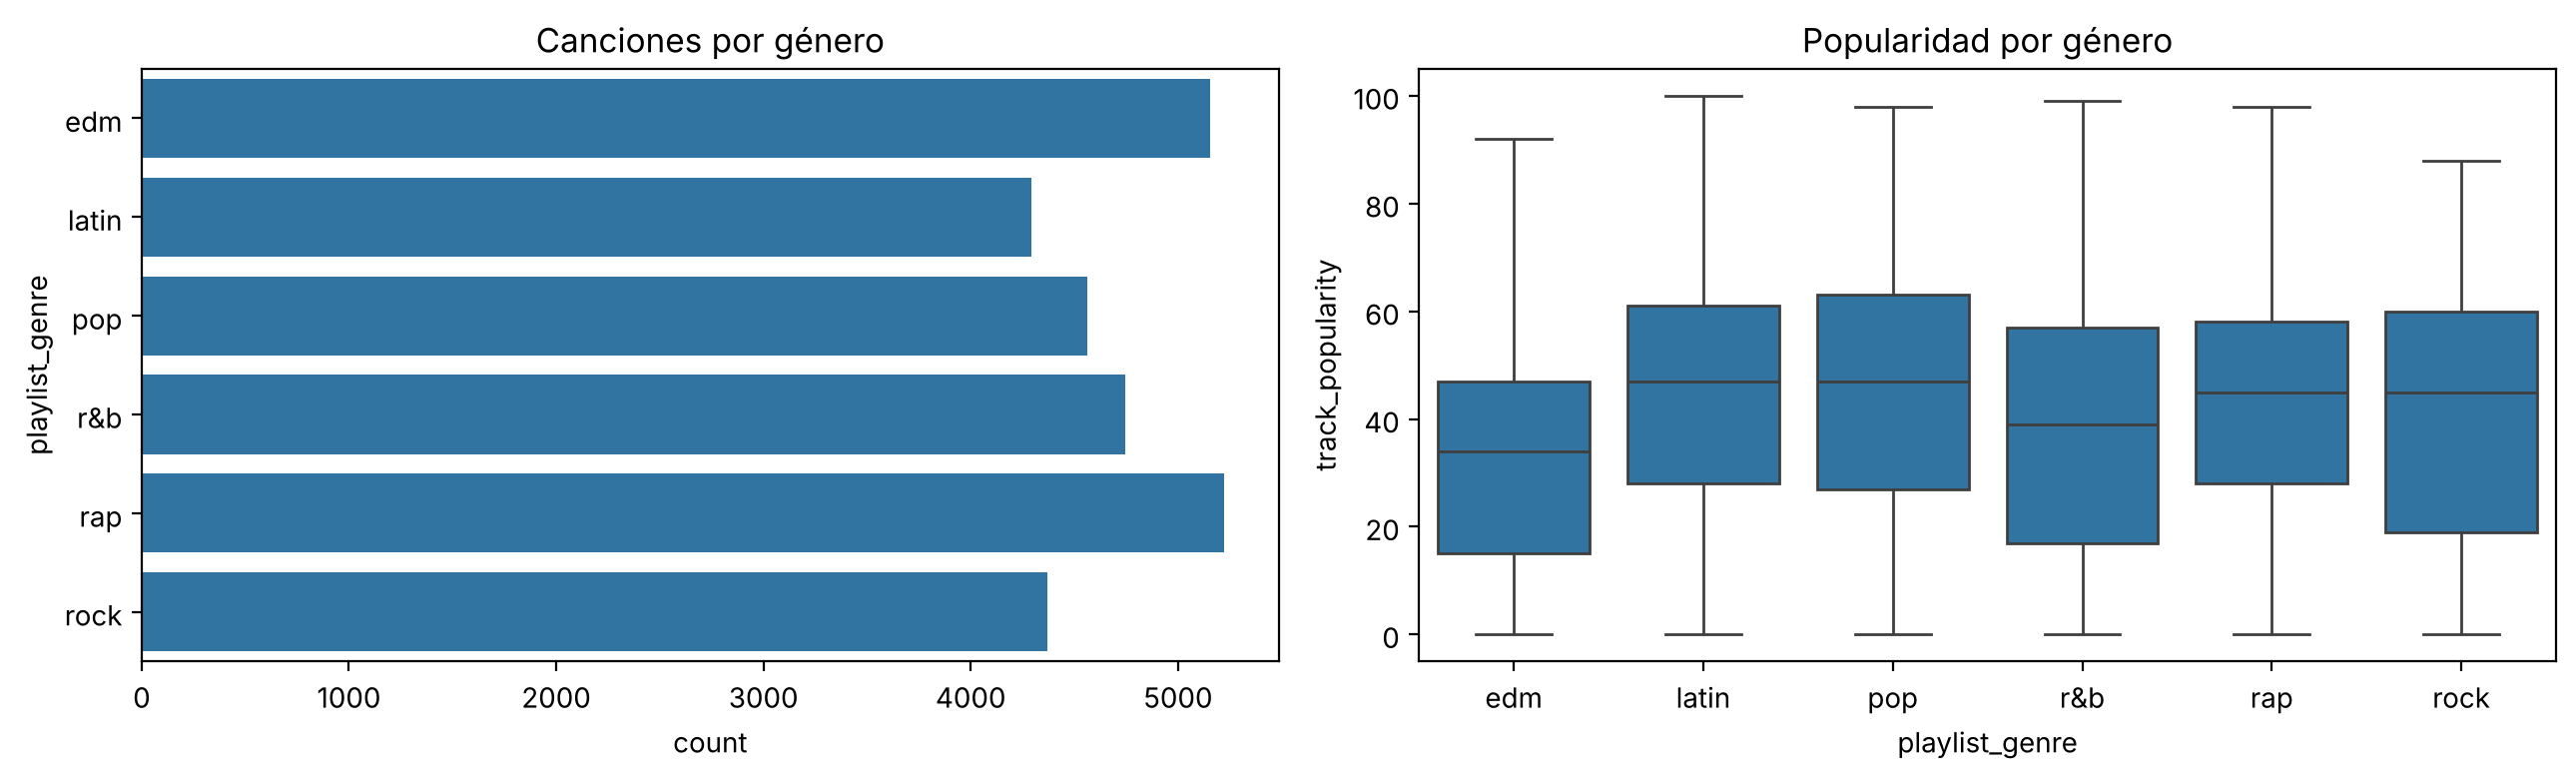

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.countplot(data=d,y='playlist_genre',ax=ax[0]);ax[0].set_title('Canciones por género')
sns.boxplot(data=d,x='playlist_genre',y='track_popularity',ax=ax[1]);ax[1].set_title('Popularidad por género');plt.tight_layout();plt.show()

In [ ]:
import os; os.makedirs('../datos',exist_ok=True)
d.to_csv('../datos/spotify_songs_limpio.csv',index=False); print('Guardado:',d.shape)

Guardado: (28352, 24)


### 5. Conclusiones de la Etapa 1
Después de la limpieza pasamos de 32 833 a 28 352 canciones únicas, con los tipos de dato corregidos y las fechas en un solo formato. Con esta base ya podemos hacer el análisis de las siguientes etapas.

(Agregar aquí lo que aprendió el equipo en este módulo.)

---
## Etapa 2: Análisis estadístico (Módulo 2)
*Sección a cargo de los compañeros del equipo. Debe incluir:*
1. Medidas de tendencia central (media, mediana, moda) con su interpretación.
2. Medidas de dispersión (rango, varianza, desviación estándar) con su interpretación.
3. Comparación entre variables o grupos (por ejemplo, entre géneros).
4. Identificación de outliers, relaciones e hipótesis, con tablas y gráficos.

Se recomienda trabajar sobre `datos/spotify_songs_limpio.csv`.

---
## Etapa 3 (Módulo 3)
*Sección a cargo de los compañeros del equipo Gelver Cifuentes.*